# AI Methods I 
###### Group Members: Ugochinyere Megwa, Sneha Sachin Shenoy, Álvaro Miñé
###### Faculty: Salvador

## Apartment Cost in New York City

#### Overview

This data was downloaded from Kaggle. Our aim is to analyse the data, clean it, explore it and model it. 



In [ ]:
# %pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
import zipfile
from pathlib import Path
from matplotlib.ticker import FuncFormatter, MaxNLocator

In [4]:
df = pd.read_csv('../figures/apartment_data.csv')

In [5]:
df_clean = df.copy()

In [ ]:
print(df)

In [ ]:
df

In [24]:
df = df.drop(['Curb Cut', 'Proposed Zoning Sqft', 'Horizontal Enlrgmt', 'Vertical Enlrgmt', 'Enlargement SQ Footage' ], axis=1)


In [ ]:
df.isnull().sum(axis=1)

In [ ]:
df[df.isnull().sum(axis=1) > 0]

In [ ]:
n_duplicates = df_clean.duplicated().sum()
print(n_duplicates)

6104


In [83]:
df = df.drop_duplicates()

In [38]:
df = df.reset_index(drop=True)

In [40]:
df = df.map(lambda x: x.upper() if isinstance(x, str) else x)

In [42]:
df['Initial Cost'] = pd.to_numeric(
    df['Initial Cost']
    .astype('string')
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False),
    errors='coerce'
)

In [44]:
df['Initial Cost Original'] = df['Initial Cost'].copy()

In [47]:
df

,Job #,Borough,House #,Street Name,Block,Lot,Bin #,Job Type,Community - Board,Fully Permitted,Initial Cost,Zoning Dist1,Job Description,Initial Cost Original
0,123768976,MANHATTAN,1598,2ND AVENUE,1545,49,1049907,A2,108,NaN,65000.0,C1-9,INTERIOR RENOVATION TO COMBINE APARTMENT 2E AN...,65000.0
1,140922893,MANHATTAN,160,E 89 ST,1517,43,1048094,A2,108,07/14/2020,85000.0,R8B,HEREBY FILING APPLICATION FOR THE INTERIOR REN...,85000.0
2,301773579,BROOKLYN,65,GATES AVENUE,1962,86,3056039,A1,302,05/23/2007,60000.0,R6,CHANGE EXISTING FOUR STORY AND BASEMENT BRICK ...,60000.0
3,301976057,BROOKLYN,1401,OCEAN AVENUE,7584,35,3206621,A2,314,02/28/2006,75000.0,NaN,COMBINING OF APARTMENT 4A &AMP; 4L.NO CHANGEIN...,75000.0
4,301989276,BROOKLYN,154,NOBLE STREET,2573,10,3065099,A1,301,09/29/2006,40000.0,C4-3,NEW C OF O FOR EXISTING BUILDING. NEW DUPLEX A...,40000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13504,123847409,MANHATTAN,225,CENTRAL PARK WEST,1196,29,1031181,A2,107,06/11/2020,60000.0,R10A,COMBINATION OF APARTMENTS 1608 AND 1610 ON 015...,60000.0
13505,141021631,MANHATTAN,51,5TH AVENUE,569,5,1009275,A2,102,12/09/2022,40000.0,R10,LEVEL 2 RENOVATIONS: PARTIAL REMOVAL OF NON-ST...,40000.0
13506,121090112,MANHATTAN,110,DUANE STREET,150,22,1001645,A2,101,07/17/2012,40000.0,C6-2A,APARTMENT RENVOATION AT APT #4R. DEMOLISH AND ...,40000.0
13507,102937342,MANHATTAN,166,BANK STREET,638,4,1078335,A2,102,02/07/2001,80000.0,C6-2,INTERIOR RENOVATION OF AN EXISTING APARTMENT. ...,80000.0


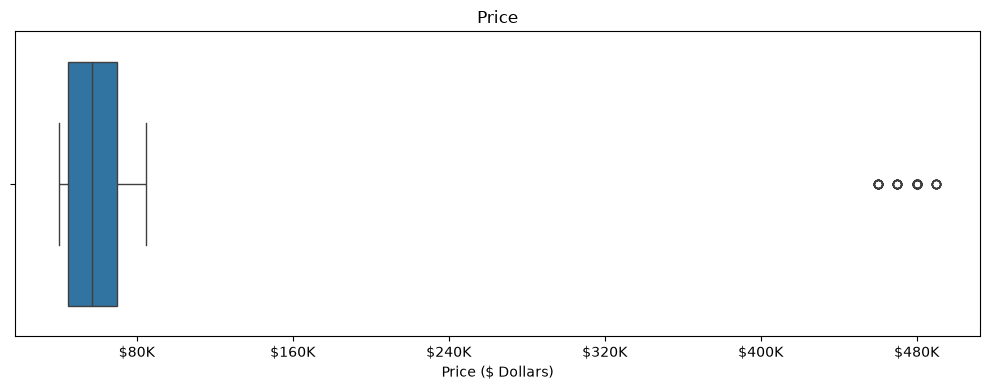

In [62]:
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()

In [76]:
price = df_clean["Initial Cost"]

# IQR rule
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = (price < q1 - 1.5 * iqr) | (price > q3 + 1.5 * iqr)
df_clean = df_clean[~iqr_outliers].reset_index(drop=True)
print(f"IQR rule:        keep {q1 - 1.5 * iqr:,.1f} to {q3 + 1.5 * iqr:,.1f} Dollars -> removes {iqr_outliers.sum():,} listings")


IQR rule:        keep 7,500.0 to 107,500.0 Dollars -> removes 59 listings


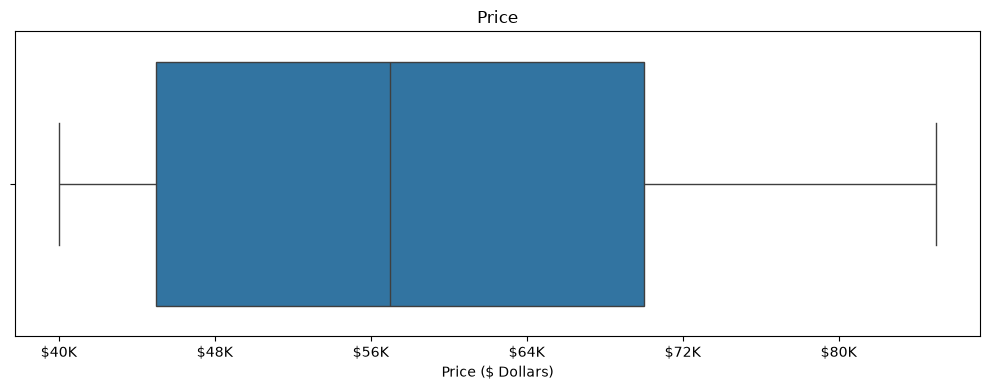

In [77]:
df_clean["Initial Cost"] = pd.to_numeric(
    df_clean["Initial Cost"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(x=df_clean["Initial Cost"], ax=ax)

ax.set_title("Price")
ax.set_xlabel("Price ($ Dollars)")

# Format tick labels as $65K
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

# Limit to roughly 8 ticks
ax.xaxis.set_major_locator(MaxNLocator(nbins=8))

plt.tight_layout()
plt.show()

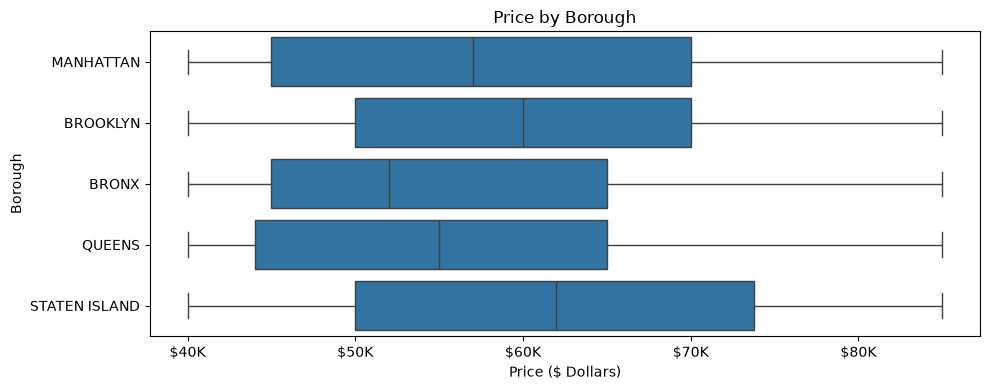

In [78]:
fig, ax = plt.subplots(figsize=(10, 4))

sns.boxplot(data=df_clean, x="Initial Cost", y="Borough", ax=ax)

ax.set_title("Price by Borough")
ax.set_xlabel("Price ($ Dollars)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"${x/1000:.0f}K"))

plt.tight_layout()
plt.show()

In [79]:
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Initial Cost"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Initial Cost")

Removed 0 listings without Initial Cost


In [80]:
rows_before = len(df_clean)
df_clean = df_clean.dropna(subset=["Borough"]).reset_index(drop=True)
print(f"Removed {rows_before - len(df_clean):,} listings without Borough")

Removed 0 listings without Borough


In [88]:
df = df.drop_duplicates()
final_columns = [
    # location
    "Job #",
    # size and typology
    "Borough", "House #", "Street Name", "Block", "Lot", "Bin #",
    "Community - Board", "Fully Permitted", "Initial Cost",
    # position in the building
    "Zoning Dist1", "Job Description", 
]

df_clean = df = df.drop_duplicates()[final_columns]
df_clean.info()

<class 'pandas.DataFrame'>
Index: 13470 entries, 0 to 19553
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Job #              13470 non-null  int64  
 1   Borough            13470 non-null  str    
 2   House #            13470 non-null  str    
 3   Street Name        13470 non-null  str    
 4   Block              13470 non-null  int64  
 5   Lot                13470 non-null  int64  
 6   Bin #              13470 non-null  int64  
 7   Community - Board  13470 non-null  int64  
 8   Fully Permitted    10728 non-null  str    
 9   Initial Cost       13470 non-null  float64
 10  Zoning Dist1       12009 non-null  str    
 11  Job Description    13470 non-null  str    
dtypes: float64(1), int64(5), str(6)
memory usage: 1.3 MB
